In [1]:
# SPDX-FileCopyrightText: 2025 Contributors to the OpenSTEF project <openstef@lfenergy.org>
#
# SPDX-License-Identifier: MPL-2.0

# School Holidays and a Christmas Forecast

Does adding school holidays as a feature change a forecast over the Christmas break?
This tutorial trains two GBLinear models on the same data. One uses school holiday
features and one does not. Both forecast the week of 21 December 2024, which falls
in the Christmas school holiday for the Noord-Holland region.

**What you'll learn:**

- Export school holidays once to CSV with `SchoolHolidayFeatureAdder.export_csv`
- Enable school holiday features with `SchoolHolidayConfig` on a workflow
- Compare two forecasts side by side and measure whether the feature changes them

```{note}
This is a single feeder over a short training window, so the result is one
data point and not a general conclusion. The training window contains one school
holiday period (autumn, 26 October to 3 November 2024).
```

**Data attribution:** School holiday data from the
[OpenHolidays API](https://openholidaysapi.org), licensed under ODbL 1.0.
Commercial use is permitted with attribution.

In [2]:
import warnings

warnings.filterwarnings("ignore")

from openstef_core.testing import configure_notebook_display, setup_notebook_logging

configure_notebook_display()
logger = setup_notebook_logging(
    __name__,
    suppress=(
        "choreographer",
        "kaleido",
        "httpx",
        "huggingface_hub",
        "fsspec",
        "filelock",
        "openstef_core.datasets",
    ),
)

## Load the dataset and define the windows

We use the Liander 2024 dataset, the same as the
{doc}`/tutorials/forecasting_quickstart`, but a different feeder. Feeders serve
different customers, so a school holiday affects them differently. We picked
Watergraafsmeer because its load dips most during the autumn holiday in the training
window (about 16%, versus about 6% to 11% for most feeders). It is in Amsterdam,
which is in the Noord-Holland school holiday region we configure below.

- **Training:** 15 September to 21 December 2024. It includes the autumn school
  holiday (26 October to 3 November).
- **Forecast:** 21 to 28 December 2024, inside the Christmas school holiday.

The predict window includes 14 days of history before the forecast start for lag features.

In [3]:
from datetime import datetime, timedelta

import pandas as pd

from openstef_core.testing import load_liander_dataset

dataset = load_liander_dataset(target="mv_feeder/OS Watergraafsmeer")

train_start = datetime.fromisoformat("2024-09-15T00:00:00Z")
forecast_start = datetime.fromisoformat("2024-12-21T00:00:00Z")
forecast_end = forecast_start + timedelta(days=7)

train_dataset = dataset.filter_by_range(start=train_start, end=forecast_start)
predict_dataset = dataset.filter_by_range(
    start=forecast_start - timedelta(days=14),
    end=forecast_end,
)

print(
    f"Training:  {train_dataset.data.shape[0]:,} rows, "
    f"{train_dataset.data.index.min():%Y-%m-%d} to {train_dataset.data.index.max():%Y-%m-%d}"
)
print(
    f"Predict:   {predict_dataset.data.shape[0]:,} rows, "
    f"{predict_dataset.data.index.min():%Y-%m-%d} to {predict_dataset.data.index.max():%Y-%m-%d}"
)

Training:  9,312 rows, 2024-09-15 to 2024-12-20
Predict:   2,016 rows, 2024-12-07 to 2024-12-27


## Export the school holidays once

The OpenHolidays API is free and public, so we ask it for one range of dates in one
request and save the result to CSV. Workflows then read that file during `fit`, so
neither training nor forecasting calls the API again. The file is cached in the
system temp directory and is only requested if it is missing.

The range covers the training window and the forecast window, with a margin on each side.

In [4]:
import tempfile
from datetime import date
from pathlib import Path

from openstef_models.transforms.time_domain import SchoolHolidayConfig, SchoolHolidayFeatureAdder

csv_path = Path(tempfile.gettempdir()) / "openstef_school_holidays_nl_nh_2024_2025.csv"
if not csv_path.exists():
    SchoolHolidayFeatureAdder(country_code="NL", subdivision_code="NL-NH").export_csv(
        csv_path, start=date(2024, 1, 1), end=date(2025, 12, 31)
    )

holidays = SchoolHolidayFeatureAdder.from_csv(csv_path, country_code="NL", subdivision_code="NL-NH")
for period in holidays.holidays:
    if period.end_date >= date(2024, 9, 1) and period.start_date <= date(2025, 1, 10):
        print(f"{period.name}: {period.start_date} to {period.end_date}")

Summer Holidays: 2024-07-20 to 2024-09-01
Autumn Holidays: 2024-10-26 to 2024-11-03
Christmas Holidays: 2024-12-21 to 2025-01-05


## Configure the two workflows

Both workflows use the same GBLinear configuration. The only difference is
`school_holidays`. The baseline leaves it unset, and the holiday model sets it to a
[`SchoolHolidayConfig`](https://openstef.github.io/openstef/api/generated/openstef_models.transforms.time_domain.SchoolHolidayConfig.html)
that reads the CSV above.

In [5]:
from openstef_core.types import LeadTime, Q
from openstef_models.presets import ForecastingWorkflowConfig, create_forecasting_workflow
from openstef_models.presets.forecasting_workflow import GBLinearForecaster
from openstef_models.workflows import CustomForecastingWorkflow


def build_workflow(model_id: str, school_holidays: SchoolHolidayConfig | None) -> CustomForecastingWorkflow:
    return create_forecasting_workflow(
        config=ForecastingWorkflowConfig(
            model_id=model_id,
            model="gblinear",
            horizons=[LeadTime.from_string("PT36H")],
            quantiles=[Q(0.5), Q(0.1), Q(0.9)],
            target_column="load",
            temperature_column="temperature_2m",
            relative_humidity_column="relative_humidity_2m",
            wind_speed_column="wind_speed_10m",
            radiation_column="shortwave_radiation",
            pressure_column="surface_pressure",
            school_holidays=school_holidays,
            verbosity=0,
            mlflow_storage=None,
            gblinear_hyperparams=GBLinearForecaster.HyperParams(n_steps=50),
        )
    )


holiday_config = SchoolHolidayConfig(country_code="NL", subdivision_code="NL-NH", csv_path=csv_path)
baseline_workflow = build_workflow("christmas_gblinear_baseline", school_holidays=None)
holiday_workflow = build_workflow("christmas_gblinear_school_holidays", school_holidays=holiday_config)

2026/11/13 12:35:27 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/egor.dmitriev/projects/opensource/openstef-cocoding/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## Train both models

Both models are fit on the same training data. The holiday model reads the CSV during
`fit`, so the holiday feature set is fixed in the checkpoint.

In [6]:
baseline_result = baseline_workflow.fit(train_dataset)
holiday_result = holiday_workflow.fit(train_dataset)

for name, result in [("Baseline", baseline_result), ("School holidays", holiday_result)]:
    if result is not None and result.metrics_test is not None:
        print(f"{name} test-set metrics:")
        print(result.metrics_test.to_dataframe())

[2026-11-13 12:35:27,581][INFO] lag fallback applied


[2026-11-13 12:35:27,865][INFO] lag fallback applied


[2026-11-13 12:35:28,498][INFO] lag fallback applied


[2026-11-13 12:35:28,767][INFO] lag fallback applied


[2026-11-13 12:35:28,860][INFO] lag fallback applied


[2026-11-13 12:35:29,496][INFO] lag fallback applied


In [7]:
assert baseline_result is not None, "Baseline training should produce a result"
assert holiday_result is not None, "School holiday training should produce a result"

## Forecast the Christmas week

Each model forecasts the same seven days, starting on the first day of the Christmas break.

In [8]:
from openstef_core.datasets import ForecastDataset

baseline_forecast: ForecastDataset = baseline_workflow.predict(predict_dataset, forecast_start=forecast_start)
holiday_forecast: ForecastDataset = holiday_workflow.predict(predict_dataset, forecast_start=forecast_start)

print(f"Baseline rows: {len(baseline_forecast.data)}, school holiday rows: {len(holiday_forecast.data)}")

Baseline rows: 672, school holiday rows: 672


In [9]:
assert len(baseline_forecast.data) > 100, "Baseline forecast should have many rows"
assert len(holiday_forecast.data) > 100, "School holiday forecast should have many rows"

## Compare the two forecasts

We score both forecasts against the measured load with two metrics from openstef-beam:

- **rMAE** scores the median forecast. It is the mean absolute error divided by the range
  of the measured load in the window.
- **rCRPS** scores all quantiles together. It is the continuous ranked probability score
  divided by the same range.

Both are scale-free, and lower is better. Both models share the same measured load, so the
normalizer is identical and the two scores compare directly. The difference between the two
forecasts shows how much the holiday feature moves the prediction.

In [10]:
from openstef_beam.metrics import rcrps, rmae

actual = predict_dataset.data["load"].loc[forecast_start:forecast_end].rename("actual")
baseline_median = baseline_forecast.median_series.rename("baseline")
holiday_median = holiday_forecast.median_series.rename("school_holidays")

# The Liander feeder stores load in watts, so convert to kilowatts for display.
comparison = pd.concat([actual, baseline_median, holiday_median], axis=1).dropna() / 1000
comparison["difference"] = comparison["school_holidays"] - comparison["baseline"]


def score(forecast: ForecastDataset, actual: pd.Series) -> dict[str, float]:
    quantiles = sorted(forecast.quantiles)
    columns = [quantile.format() for quantile in quantiles]
    aligned = pd.concat([actual, forecast.data[columns]], axis=1).dropna()
    return {
        "rMAE": rmae(aligned["actual"].to_numpy(), aligned[Q(0.5).format()].to_numpy()),
        "rCRPS": rcrps(aligned["actual"].to_numpy(), aligned[columns].to_numpy(), quantiles),
    }


summary = pd.DataFrame(
    {
        "Baseline": score(baseline_forecast, actual),
        "School holidays": score(holiday_forecast, actual),
    }
).T
print(f"Compared rows: {len(comparison)}")
print(summary.round(4).to_string())
print(f"\nMean difference, school holidays minus baseline: {comparison['difference'].mean():.3f} kW")
print(f"Mean absolute difference between the two forecasts: {comparison['difference'].abs().mean():.3f} kW")
print(f"Largest absolute difference: {comparison['difference'].abs().max():.3f} kW")

Compared rows: 672
                   rMAE   rCRPS
Baseline         0.3273  0.2388
School holidays  0.2780  0.2081

Mean difference, school holidays minus baseline: -49.782 kW
Mean absolute difference between the two forecasts: 49.782 kW
Largest absolute difference: 71.905 kW


## Visualize the comparison

The top panel shows the measured load and both median forecasts. The bottom panel shows
the difference, school holidays minus baseline.

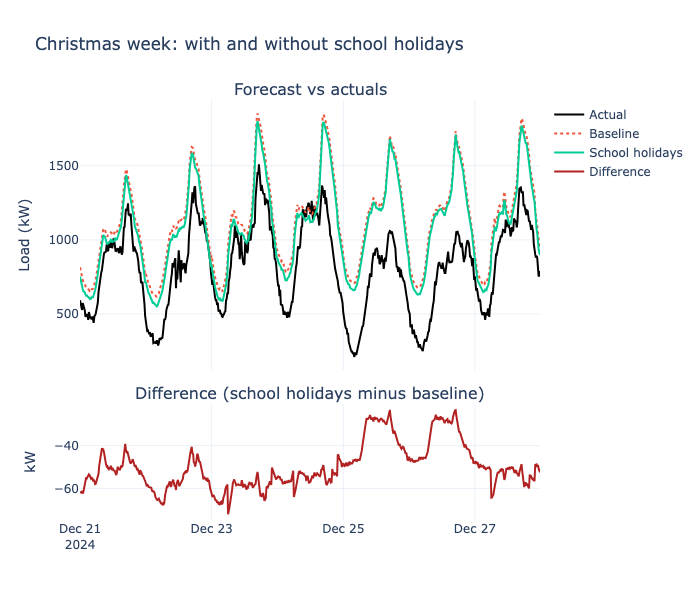

In [11]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.08,
    row_heights=[0.7, 0.3],
    subplot_titles=("Forecast vs actuals", "Difference (school holidays minus baseline)"),
)
fig.add_trace(
    go.Scatter(x=comparison.index, y=comparison["actual"], name="Actual", line={"color": "black"}), row=1, col=1
)
fig.add_trace(
    go.Scatter(x=comparison.index, y=comparison["baseline"], name="Baseline", line={"dash": "dot"}), row=1, col=1
)
fig.add_trace(
    go.Scatter(x=comparison.index, y=comparison["school_holidays"], name="School holidays"),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scatter(x=comparison.index, y=comparison["difference"], name="Difference", line={"color": "firebrick"}),
    row=2,
    col=1,
)
fig.update_layout(height=600, template="plotly_white", title="Christmas week: with and without school holidays")
fig.update_yaxes(title_text="Load (kW)", row=1, col=1)
fig.update_yaxes(title_text="kW", row=2, col=1)
fig.show()

## Is the difference more than noise?

GBLinear's default `shuffle` feature selector is random, and the forecaster does not
pass `random_state` through to XGBoost. Each fit is therefore a fresh random draw, and
repeating a fit can change its scores. We fit both variants five times and compare the
paired difference in rMAE and rCRPS on the forecast week. The spread across fits shows how
much of a difference is noise.

In [12]:
import numpy as np

fit_rows = []
for fit in range(5):
    row: dict[str, float] = {"fit": fit}
    for label, school_holidays in [("baseline", None), ("school_holidays", holiday_config)]:
        workflow = build_workflow(f"christmas_gblinear_{label}_fit{fit}", school_holidays)
        workflow.fit(train_dataset)
        for metric, value in score(workflow.predict(predict_dataset, forecast_start=forecast_start), actual).items():
            row[f"{label}_{metric}"] = value
    fit_rows.append(row)

fit_results = pd.DataFrame(fit_rows)
for metric in ["rMAE", "rCRPS"]:
    fit_results[f"{metric}_difference"] = fit_results[f"school_holidays_{metric}"] - fit_results[f"baseline_{metric}"]
print(fit_results.round(4).to_string(index=False))
print()
for metric in ["rMAE", "rCRPS"]:
    difference = fit_results[f"{metric}_difference"]
    print(
        f"{metric} difference (school holidays minus baseline): "
        f"mean {difference.mean():.4f}, std {difference.std():.4f}"
    )

[2026-11-13 12:35:32,255][INFO] lag fallback applied


[2026-11-13 12:35:32,357][INFO] lag fallback applied


[2026-11-13 12:35:32,949][INFO] lag fallback applied


[2026-11-13 12:35:33,283][INFO] lag fallback applied


[2026-11-13 12:35:33,384][INFO] lag fallback applied


[2026-11-13 12:35:33,981][INFO] lag fallback applied


... (21 outputs left out)

[2026-11-13 12:35:41,482][INFO] lag fallback applied


[2026-11-13 12:35:41,573][INFO] lag fallback applied


[2026-11-13 12:35:42,160][INFO] lag fallback applied


 fit  baseline_rMAE  baseline_rCRPS  school_holidays_rMAE  school_holidays_rCRPS  rMAE_difference  rCRPS_difference
   0         0.3306          0.2408                0.2777                 0.2080          -0.0529           -0.0328
   1         0.3301          0.2404                0.2785                 0.2085          -0.0515           -0.0318
   2         0.3300          0.2403                0.2782                 0.2082          -0.0518           -0.0320
   3         0.3291          0.2395                0.2789                 0.2086          -0.0502           -0.0310
   4         0.3289          0.2398                0.2779                 0.2082          -0.0511           -0.0316

rMAE difference (school holidays minus baseline): mean -0.0515, std 0.0010
rCRPS difference (school holidays minus baseline): mean -0.0318, std 0.0007


In [13]:
assert len(fit_results) == 5, "Expected one row per fit"
assert np.isfinite(fit_results.drop(columns="fit").to_numpy()).all(), "Metric values should be finite"

## Placebo: a normal school week

If the gain above comes from the holiday, it should not appear in a week with no holiday.
We retrain both models on data up to 9 December 2024 and forecast 9 to 16 December, a normal
school week. Training still includes the autumn holiday, but not the Christmas one. We run the
same five paired fits.

In [14]:
placebo_start = datetime.fromisoformat("2024-12-09T00:00:00Z")
placebo_end = placebo_start + timedelta(days=7)
placebo_train = dataset.filter_by_range(start=train_start, end=placebo_start)
placebo_predict = dataset.filter_by_range(start=placebo_start - timedelta(days=14), end=placebo_end)
placebo_actual = placebo_predict.data["load"].loc[placebo_start:placebo_end].rename("actual")

placebo_rows = []
for fit in range(5):
    row: dict[str, float] = {"fit": fit}
    for label, school_holidays in [("baseline", None), ("school_holidays", holiday_config)]:
        workflow = build_workflow(f"placebo_gblinear_{label}_fit{fit}", school_holidays)
        workflow.fit(placebo_train)
        forecast = workflow.predict(placebo_predict, forecast_start=placebo_start)
        for metric, value in score(forecast, placebo_actual).items():
            row[f"{label}_{metric}"] = value
    placebo_rows.append(row)

placebo_results = pd.DataFrame(placebo_rows)
for metric in ["rMAE", "rCRPS"]:
    placebo_results[f"{metric}_difference"] = (
        placebo_results[f"school_holidays_{metric}"] - placebo_results[f"baseline_{metric}"]
    )
print(placebo_results.round(4).to_string(index=False))
print()
for metric in ["rMAE", "rCRPS"]:
    difference = placebo_results[f"{metric}_difference"]
    print(
        f"{metric} difference, normal week (school holidays minus baseline): "
        f"mean {difference.mean():.4f}, std {difference.std():.4f}, "
        f"school holidays better in {(difference < 0).sum()} of {len(difference)} fits"
    )

[2026-11-13 12:35:42,500][INFO] lag fallback applied


[2026-11-13 12:35:42,581][INFO] lag fallback applied


[2026-11-13 12:35:43,135][INFO] lag fallback applied


[2026-11-13 12:35:43,428][INFO] lag fallback applied


[2026-11-13 12:35:43,512][INFO] lag fallback applied


[2026-11-13 12:35:44,074][INFO] lag fallback applied


... (21 outputs left out)

[2026-11-13 12:35:50,706][INFO] lag fallback applied


[2026-11-13 12:35:50,787][INFO] lag fallback applied


[2026-11-13 12:35:51,290][INFO] lag fallback applied


 fit  baseline_rMAE  baseline_rCRPS  school_holidays_rMAE  school_holidays_rCRPS  rMAE_difference  rCRPS_difference
   0         0.2685          0.1517                0.2741                 0.1547           0.0057            0.0030
   1         0.2695          0.1522                0.2742                 0.1546           0.0047            0.0025
   2         0.2689          0.1519                0.2749                 0.1549           0.0060            0.0030
   3         0.2693          0.1520                0.2739                 0.1547           0.0046            0.0027
   4         0.2689          0.1519                0.2749                 0.1548           0.0059            0.0029

rMAE difference, normal week (school holidays minus baseline): mean 0.0054, std 0.0007, school holidays better in 0 of 5 fits
rCRPS difference, normal week (school holidays minus baseline): mean 0.0028, std 0.0003, school holidays better in 0 of 5 fits


In [15]:
assert len(placebo_results) == 5, "Expected one row per placebo fit"
assert np.isfinite(placebo_results.drop(columns="fit").to_numpy()).all(), "Placebo metric values should be finite"

## What the comparison shows

- **In the Christmas week, the holiday feature helps.** The school-holiday forecast has a lower
  rMAE (about 0.28 against 0.33) and rCRPS (about 0.21 against 0.24) than the baseline. Across
  the five paired fits, the holiday variant was better on both metrics every time. The mean rMAE
  gap was about 0.05.
- **In a normal school week, the holiday feature hurts a little.** In the placebo week, the
  holiday variant has a higher rMAE (about 0.276 against 0.270, mean difference about +0.006).
  It was worse in all five fits, and the rCRPS gap is also positive (about +0.003). So the
  Christmas gain is not a general improvement from extra features.
- **Run-to-run noise is small compared with both effects.** The fit-to-fit spread of the
  difference is about 0.001 to 0.002 in both weeks. The effects are about 0.05 and 0.006, so
  random feature selection does not explain either result. The exact numbers change slightly on
  each execution because GBLinear's feature selector is random.
- **The baseline misses the holiday drop.** In the Christmas week, the school-holiday forecast
  sits on average about 50 kW below the baseline, with a largest gap of over 70 kW. The
  baseline has no information about when the holiday starts, so this gap is consistent with the
  feature capturing the Christmas drop. This notebook does not isolate that cause.

The trade-off is clear on this feeder: the feature gains a lot in a holiday week and loses a
little in a normal week. Whether that is worth it depends on how often holidays fall in the
forecast horizon. This is one feeder, one holiday period in training, and one forecast week
for each case. The feeder was chosen from training-window data before the comparison was run.
Other feeders can respond differently, so test more holidays and feeders before you choose a
default.

## Next steps

- {doc}`/tutorials/feature_engineering` — the school holiday transform and the
  one-hot option for each holiday name.
- {doc}`/tutorials/forecasting_quickstart` — the baseline workflow without holidays.